# Assignment 1 — Data Exploration and Cleaning: Quotes

Each row represents a quoting-post → quoted-post relationship. We examine structure, missing values, duplicates, consistency, outliers, and opportunities for integration and derived information.

Requirements: Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Adjust the paths below and run cells in order. Original files remain unchanged. `EXPORT = True` writes compressed CSVs; it is off by default to avoid creating large data copies.


In [35]:
from pathlib import Path
from urllib.parse import urlsplit
import xml.etree.ElementTree as ET
import json
import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_DIR = Path("../../ProjectData")
ARFF_PATH = DATA_DIR / "additional_truths.arff"
EXPORT = True


In [3]:
with (DATA_DIR / "quotes.json").open(encoding="utf-8") as file:
    data = json.load(file, parse_int=str, parse_float=str)
df_raw = pd.DataFrame(data, dtype="string")
del data
original_columns = df_raw.columns.tolist()
print("Rows and columns:", df_raw.shape)
display(df_raw.head())
display(pd.DataFrame({"Missing": df_raw.isna().sum(), "Blank": [df_raw[c].str.strip().eq("").sum() for c in df_raw], "Distinct": df_raw.nunique()}))


Rows and columns: (10508, 5)


,timestamp,quoted_user,quoting_user,quoting_truth,quoted_truth_external_id
0,2022-07-22 09:43:00,125,131,16333,108688461672926241
1,2022-08-20 18:00:00,300,300,14949,108857444588213255
2,2022-07-14 21:13:00,2106,8212,367606,108648254976307349
3,2022-09-12 22:40:00,933,27,1593,108790130246424349
4,2022-11-11 00:00:00,134003,6657,763581,109324987069121051


,Missing,Blank,Distinct
timestamp,0,0,8528
quoted_user,0,0,2873
quoting_user,0,0,409
quoting_truth,0,0,10508
quoted_truth_external_id,0,0,9760


In [4]:
removed_duplicates = int(df_raw.duplicated().sum())
df_clean = df_raw.drop_duplicates().reset_index(drop=True).copy()
for col in df_clean:
    df_clean[col] = df_clean[col].str.strip().replace("", pd.NA)
id_columns = ['quoted_user', 'quoting_user', 'quoting_truth']
for col in id_columns:
    values = df_clean[col].str.replace(r"\.0+$", "", regex=True)
    assert values.str.fullmatch(r"\d+", na=False).all(), f"Inspect invalid {col} values."
    df_clean[col] = pd.to_numeric(values, errors="raise").astype("Int64")
    assert df_clean[col].gt(0).all()
print("Exact duplicate rows removed:", removed_duplicates)
features = pd.DataFrame({"row_id": np.arange(len(df_clean))})


Exact duplicate rows removed: 0


## Role-specific identifiers and timestamps

`quoting_truth` is an internal main-corpus post ID; `quoted_truth_external_id` is an external post ID. The two user columns have different roles. We preserve external IDs as strings and avoid many-to-many joins by summarizing candidate authors before comparing them.


In [6]:
assert df_clean["quoted_truth_external_id"].str.fullmatch(r"\d+", na=False).all()
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"], format="ISO8601", errors="raise")
features["timestamp_at_midnight"] = df_clean["timestamp"].eq(df_clean["timestamp"].dt.normalize())
features["timestamp_after_reference_date"] = df_clean["timestamp"].ge(pd.Timestamp("2026-11-12"))
features["self_quote"] = df_clean["quoted_user"].eq(df_clean["quoting_user"])
features["quote_month"] = df_clean["timestamp"].dt.strftime("%Y-%m")
print("Repeated quoting post IDs:", df_clean["quoting_truth"].duplicated().sum())
target_counts = df_clean.groupby("quoting_truth")["quoted_truth_external_id"].nunique()
features["quoting_post_has_multiple_targets"] = df_clean["quoting_truth"].map(target_counts).gt(1)
print("Timestamp range:", df_clean["timestamp"].min(), "to", df_clean["timestamp"].max())
print("Self-quotes retained:", features["self_quote"].sum())


Repeated quoting post IDs: 0
Timestamp range: 2022-06-08 13:39:00 to 2022-12-06 00:00:00
Self-quotes retained: 937


In [7]:
user_ids = []
context = ET.iterparse(DATA_DIR / "users.xml", events=("start", "end"))
_, root = next(context)
for event, elem in context:
    if event == "end" and elem.tag == "row":
        user_ids.append(int(elem.findtext("id_user")))
        root.clear()
assert len(user_ids) == len(set(user_ids))
user_ids = pd.Index(user_ids, dtype="int64")
del context, root, elem


In [8]:
features["quoted_user_absent"] = ~df_clean["quoted_user"].isin(user_ids)
features["quoting_user_absent"] = ~df_clean["quoting_user"].isin(user_ids)
display(features[["quoted_user_absent", "quoting_user_absent"]].sum().to_frame("Relationships"))
unknown_users = set(df_clean.loc[features["quoted_user_absent"], "quoted_user"]) | set(df_clean.loc[features["quoting_user_absent"], "quoting_user"])
print("Unknown user IDs:", sorted(unknown_users))
needed_internal = set(df_clean["quoting_truth"].astype("string"))
needed_external = set(df_clean["quoted_truth_external_id"])


,Relationships
quoted_user_absent,0
quoting_user_absent,9


Unknown user IDs: [1173]


In [9]:
arff_rows = []
in_data = False
with ARFF_PATH.open(encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()
        if not in_data:
            in_data = line.lower() == "@data"
            continue
        if not line or line.startswith("%"):
            continue
        first = line.split(",", 2)
        tail = line.rsplit(",", 3)
        assert first[0].isdigit() and len(tail) == 4
        arff_rows.append((first[0], tail[1].strip("'\""), tail[2], first[1].strip("'\"")))
arff_ref = pd.DataFrame(arff_rows, columns=["source_id", "external_id", "author", "timestamp"], dtype="string")
del arff_rows
assert arff_ref["source_id"].is_unique
assert arff_ref["source_id"].eq(arff_ref["external_id"]).all()
arff_ref["author"] = pd.to_numeric(arff_ref["author"].str.replace(r"\.0+$", "", regex=True)).astype("Int64")
arff_ref["timestamp"] = pd.to_datetime(arff_ref["timestamp"], format="ISO8601", errors="raise")


In [10]:
main_ids, parts = set(), []
for chunk in pd.read_csv(DATA_DIR / "truths.csv", usecols=["id", "external_id", "url", "author", "timestamp"], dtype="string", keep_default_na=False, chunksize=100000):
    chunk["id"] = chunk["id"].str.replace(r"\.0+$", "", regex=True)
    assert chunk["id"].str.fullmatch(r"\d+", na=False).all()
    main_ids.update(chunk["id"])
    external = chunk["external_id"].where(chunk["external_id"].str.fullmatch(r"\d+", na=False))
    url_id = chunk["url"].str.extract(r"(?i)^https?://(?:www\.)?truthsocial\.com/@[^/?#]+/posts/(\d+)/?$", expand=False)
    url_id = url_id.combine_first(chunk["url"].where(chunk["url"].str.fullmatch(r"\d+", na=False)))
    mismatch = external.notna() & url_id.notna() & external.ne(url_id).fillna(False)
    chunk["external_id"] = external.combine_first(url_id).mask(mismatch)
    keep = chunk["id"].isin(needed_internal) | chunk["external_id"].isin(needed_external)
    parts.append(chunk.loc[keep, ["id", "external_id", "author", "timestamp"]].copy())
main_ref = pd.concat(parts, ignore_index=True).drop_duplicates()
del parts, chunk
main_ref["author"] = pd.to_numeric(main_ref["author"].str.replace(r"\.0+$", "", regex=True).replace("", pd.NA), errors="raise").astype("Int64")
main_ref["timestamp"] = pd.to_datetime(main_ref["timestamp"], format="ISO8601", errors="raise")
print("Distinct main-corpus IDs:", len(main_ids))


Distinct main-corpus IDs: 1038821


## Quoting-post authors and quoted-post authors

Quoting posts are joined through internal IDs. Quoted posts are checked through external IDs; multiple records with one unanimous author can support an author comparison, but do not establish a unique internal post key. Unavailable or conflicting authors are kept as separate statuses.


In [12]:
internal_authors = main_ref.groupby("id")["author"].agg(["first", "nunique"])
internal_author = internal_authors["first"].where(internal_authors["nunique"].eq(1))
quoting_key = df_clean["quoting_truth"].astype("string")
actual_quoting_author = quoting_key.map(internal_author)
features["quoting_post_absent"] = ~quoting_key.isin(main_ids)
features["quoting_author_unavailable"] = actual_quoting_author.isna()
features["quoting_author_mismatch"] = actual_quoting_author.notna() & df_clean["quoting_user"].ne(actual_quoting_author).fillna(False)

quoted_authors = pd.concat([
    main_ref[["external_id", "author"]], arff_ref[["external_id", "author"]]
], ignore_index=True).dropna().drop_duplicates()
quoted_group = quoted_authors.groupby("external_id")["author"].agg(["first", "nunique"])
quoted_key = df_clean["quoted_truth_external_id"]
author_candidates = quoted_key.map(quoted_group["nunique"])
quoted_author = quoted_key.map(quoted_group["first"]).where(author_candidates.eq(1))
features["quoted_post_status"] = "absent"
target_present = quoted_key.isin(main_ref["external_id"]) | quoted_key.isin(arff_ref["external_id"])
features.loc[target_present & author_candidates.isna(), "quoted_post_status"] = "author_unavailable"
features.loc[author_candidates.eq(1), "quoted_post_status"] = "unanimous_author"
features.loc[author_candidates.gt(1), "quoted_post_status"] = "ambiguous_authors"
features["quoted_author_mismatch"] = quoted_author.notna() & df_clean["quoted_user"].ne(quoted_author).fillna(False)
features["quoted_post_in_arff"] = quoted_key.isin(arff_ref["external_id"])
display(features[["quoting_post_absent", "quoting_author_mismatch", "quoted_author_mismatch", "quoted_post_in_arff"]].sum().to_frame("Relationships"))
display(features["quoted_post_status"].value_counts().to_frame("Relationships"))


,Relationships
quoting_post_absent,914
quoting_author_mismatch,0
quoted_author_mismatch,6
quoted_post_in_arff,337


,Relationships
quoted_post_status,
absent,8139
unanimous_author,2369


## Temporal comparisons and recovery limits

Quote timestamps and post timestamps are compared as recorded; no timezone is invented. Disagreement can reflect limited time precision, collection conventions, or source errors. We preserve both role-specific user IDs when sources conflict.

ARFF supplies additional quoted-post references, not new evidence for the actor of unrelated events. Matching text, a username, or a quoted target alone cannot recover a missing internal post ID.


In [14]:
quoting_time = quoting_key.map(main_ref.groupby("id")["timestamp"].min())
target_times = pd.concat([
    main_ref[["external_id", "timestamp"]], arff_ref[["external_id", "timestamp"]]
], ignore_index=True).dropna().groupby("external_id")["timestamp"].min()
quoted_time = quoted_key.map(target_times)
features["quote_before_reported_quoting_post"] = df_clean["timestamp"].lt(quoting_time)
features["quote_before_all_reported_target_times"] = df_clean["timestamp"].lt(quoted_time)
features["quoted_post_present_in_main"] = quoted_key.isin(main_ref["external_id"])
print("Relationships recovered in ARFF only:", (features["quoted_post_in_arff"] & ~features["quoted_post_present_in_main"]).sum())
display(features[["quote_before_reported_quoting_post", "quote_before_all_reported_target_times", "timestamp_at_midnight"]].sum().to_frame("Relationships"))


Relationships recovered in ARFF only: 328


,Relationships
quote_before_reported_quoting_post,0
quote_before_all_reported_target_times,255
timestamp_at_midnight,1755


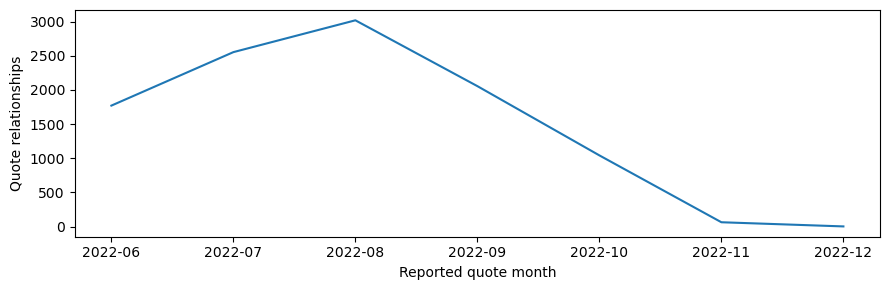

,Quotes per observed quoting user
count,409.000000
mean,25.691932
std,77.720546
min,1.000000
50%,4.000000
90%,63.000000
95%,98.800000
99%,315.680000
max,939.000000


,Quote relationships per external target
quoted_truth_external_id,
108789700493889917,21
108790947668067601,12
108906909057160138,11
108647350940945943,9
108485154625673944,8
108689194787620302,8
109009299566785023,8
108934529109328831,7
108828041518355960,6


In [15]:
monthly_quotes = df_clean["timestamp"].dt.to_period("M").value_counts().sort_index()
monthly_quotes.index = monthly_quotes.index.astype(str)
monthly_quotes.plot(figsize=(9, 3))
plt.xlabel("Reported quote month")
plt.ylabel("Quote relationships")
plt.tight_layout()
plt.show()
quotes_per_user = df_clean.groupby("quoting_user").size()
target_frequency = df_clean.groupby("quoted_truth_external_id").size()
display(quotes_per_user.describe(percentiles=[.5, .9, .95, .99]).to_frame("Quotes per observed quoting user"))
display(target_frequency.nlargest(10).to_frame("Quote relationships per external target"))
q1, q3 = quotes_per_user.quantile([.25, .75])
features["high_quote_activity_user"] = df_clean["quoting_user"].isin(quotes_per_user[quotes_per_user > q3 + 1.5 * (q3 - q1)].index)


## Final validation and exports

We preserve the original column structure. Features retain `row_id`, the zero-based row position in the cleaned export. Unresolved links remain in the cleaned data and are also listed for review.


In [17]:
df_final = df_clean[original_columns].copy()
assert len(df_final) == len(df_raw) - removed_duplicates
assert df_final[id_columns].notna().all().all()
assert df_final[id_columns].gt(0).all().all()
assert len(features) == len(df_final)
assert features["row_id"].tolist() == list(range(len(df_final)))
review_mask = (
    features["quoted_user_absent"]
    | features["quoting_user_absent"]
    | features["quoting_post_absent"]
    | features["quoting_author_unavailable"]
    | features["quoting_author_mismatch"]
    | features["quoted_author_mismatch"]
    | ~features["quoted_post_status"].eq("unanimous_author")
    | features["timestamp_after_reference_date"]
    | features["quoting_post_has_multiple_targets"]
    | features["quote_before_reported_quoting_post"]
    | features["quote_before_all_reported_target_times"]
)
issues = pd.concat([features.loc[review_mask], df_final.loc[review_mask]], axis=1)
quality_summary = pd.Series({
    "Original rows": len(df_raw), "Exact duplicates removed": removed_duplicates,
    "Cleaned rows": len(df_final), "Rows for review": int(review_mask.sum()),
    "Missing cells after cleaning": int(df_final.isna().sum().sum())
}, name="Count")
display(quality_summary.to_frame())


,Count
Original rows,10508
Exact duplicates removed,0
Cleaned rows,10508
Rows for review,8548
Missing cells after cleaning,0


In [18]:
OUTPUT_DIR = Path.cwd() / "output_quotes"
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    df_final.to_csv(OUTPUT_DIR / "quotes_clean.csv.gz", index=False, chunksize=50000)
    features.to_csv(OUTPUT_DIR / "quotes_features.csv.gz", index=False, chunksize=50000)
    issues.to_csv(OUTPUT_DIR / "quotes_issues.csv.gz", index=False)
    quality_summary.to_csv(OUTPUT_DIR / "quotes_quality_summary.csv", index_label="Check")
    print("Exported to:", OUTPUT_DIR.resolve())
else:
    print("Analysis and cleaning complete. Set EXPORT = True to save datasets.")


Exported to: /Users/alespinello/Desktop/Truth-Social-Analysis-and-Data-Warehousing---Decision-Support-Systems-/01_assignment/output_quotes


## Conclusions and Assignment 1 coverage

**Observed results:** Original rows: 10,508; Exact duplicates removed: 0; Cleaned rows: 10,508; Rows for review: 8,548; Missing cells after cleaning: 0.

The notebook distinguishes quoting and quoted roles, internal and external post namespaces, absent targets, ambiguous authors, author disagreements, and reported temporal inconsistencies. Self-quotes and high activity are retained. No user is replaced by an assumed author. Topic or geographic inference is unsupported by this relationship-only file; target-post text analysis belongs to the post corpus.

This notebook covers structure and types, missing values, duplicates and mappings, data-specific anomalies, outliers, post/user integrity where applicable, recovery assessments, derived features, and validated cleaning. Only supplied files are used. The full ARFF-to-Truths integration is implemented in `04_additional_truths_complete.ipynb`; this notebook's reference checks do not replace it.

Compressed CSVs are readable directly with `pd.read_csv(path)`. Original invalid values and unresolved cases remain traceable in features or issue tables. The sources are the supplied dataset, related original datasets, the Assignment 1 instructions, and its original exploration/cleaning notebooks.
